# FAYE Marie Pierre Gnilane Ndew 
# 12213642

# Partie 1 – Descente de gradient en une dimension

## Question 1 [Calcul] [Visualisation]

$$
\begin{aligned}
(x-1)(x-2) &= x^2 - 2x - x + 2 \\
           &= x^2 - 3x + 2 \\[8pt]
(x-3)(x-5) &= x^2 - 5x - 3x + 15 \\
           &= x^2 - 8x + 15 \\[8pt]
E(x) &= (x^2 - 3x + 2)(x^2 - 8x + 15) \\
     &= x^4 - 8x^3 + 15x^2 \;-\; 3x^3 + 24x^2 - 45x \;+\; 2x^2 - 16x + 30 \\
     &= x^4 + (-8 - 3)x^3 + (15 + 24 + 2)x^2 + (-45 - 16)x + 30 \\
     &= x^4 - 11x^3 + 41x^2 - 61x + 30 \\[8pt]
E'(x) &= 4x^{3} - 11 \cdot 3x^{2} + 41 \cdot 2x - 61 \\
      &= 4x^3 - 33x^2 + 82x - 61 \\[8pt]
E''(x) &= 4 \cdot 3x^{2} - 33 \cdot 2x + 82 \\
       &= 12x^2 - 66x + 82
\end{aligned}
$$

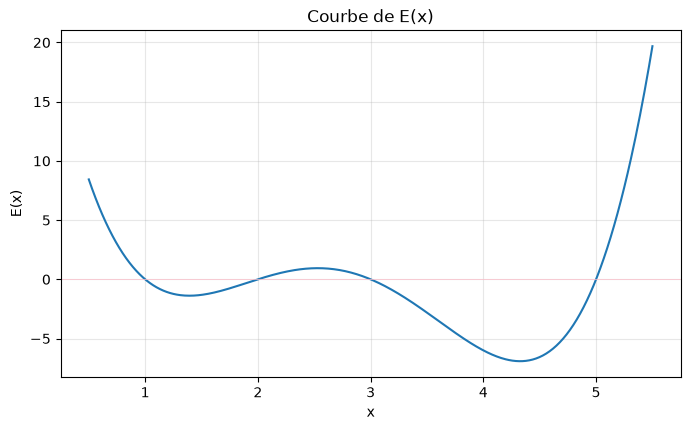

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

def E(x):   return x**4 - 11*x**3 + 41*x**2 - 61*x + 30
def dE(x):  return 4*x**3 - 33*x**2 + 82*x - 61
def d2E(x): return 12*x**2 - 66*x + 82

xx = np.linspace(0.5, 5.5, 500)
plt.plot(xx, E(xx))
plt.axhline(0, color='pink', lw=0.5)
plt.xlabel('x'); plt.ylabel('E(x)'); plt.title('Courbe de E(x)')
plt.grid(alpha=0.3); plt.show()

**Réponse :** on voit **deux minima locaux** : $x_1^* \approx 1{,}39$ et $x_2^* \approx 4{,}33$, séparés par un maximum local en $x \approx 2{,}53$.
Le **minimum global** est $x_2^* \approx 4{,}33$.

In [33]:
# On cherche les x où la pente est nulle : E'(x) = 0
# E'(x) = 4x^3 - 33x^2 + 82x - 61  -> on donne à numpy les coefficients
racines = np.sort(np.roots([4, -33, 82, -61]))

# Pour chaque point trouvé, on regarde si c'est un creux ou une bosse
for r in racines:
    print("Point x =", round(r, 2))
    print("   E(x)   =", round(E(r), 2))
    print("   E''(x) =", round(d2E(r), 2))

    if d2E(r) > 0:
        print("   -> c'est un MINIMUM local (la courbe forme un creux)")
    else:
        print("   -> c'est un MAXIMUM local (la courbe forme une bosse)")
    print()                     # ligne vide pour séparer

Point x = 1.39
   E(x)   = -1.38
   E''(x) = 13.36
   -> c'est un MINIMUM local (la courbe forme un creux)

Point x = 2.53
   E(x)   = 0.94
   E''(x) = -8.17
   -> c'est un MAXIMUM local (la courbe forme une bosse)

Point x = 4.33
   E(x)   = -6.91
   E''(x) = 21.07
   -> c'est un MINIMUM local (la courbe forme un creux)



`np.roots` donne les trois points où $E'(x) = 0$ : $x \approx 1{,}39$, $x \approx 2{,}53$ et $x \approx 4{,}33$.

En calculant $E''$ en chacun de ces points, on trouve :
- $E''(1{,}39) \approx 13{,}36 > 0$ : minimum local ;
- $E''(2{,}53) \approx -8{,}17 < 0$ : maximum local ;
- $E''(4{,}33) \approx 21{,}07 > 0$ : minimum local.

Le **minimum global** est $x^* \approx 4{,}33$, car c'est là que $E$ est la plus basse :
$$E(4{,}33) \approx -6{,}91 \quad < \quad E(1{,}39) \approx -1{,}38$$

## Question 2 [Code]

À chaque itération : $x_{i+1} = x_i - \eta E'(x_i)$. On s'arrête si le pas est petit ($|x_{i+1}-x_i|<\varepsilon$), si on a fait trop d'itérations, ou si $x$ explose (divergence).

In [34]:
def dE(x):
    return 4*x**3-33*x**2+82*x-61

def descente_gradient(dE, x0, eta, eps=0.01, nmax=1000):
    i = 1
    list_x = [x0]
    list_x.append(x0 - eta*dE(x0))

    # On continue tant que : pas trop d'itérations, le pas est encore grand, et x n'a pas explosé
    while(i < nmax and abs(list_x[i] - list_x[i-1]) > eps and abs(list_x[i])<=1e10):
        list_x.append(list_x[i] - eta*dE(list_x[i]))
        i += 1
    x_min = list_x[-1]
    
    if(abs(x_min) > 1e10) :
        print("erreur on a une divergence")
        
    if i >= nmax:
        print("attention : arrêt par nmax, pas de convergence")
        
    return x_min,i,list_x

## Question 3 [Prédiction] (écrite avant l'exécution)

Pour prédire le comportement, je regarde deux choses : de quel côté part la descente, et la taille du premier pas.

En partant de $x_0 = 5$, la pente est positive ($E'(5) = 24$), donc la descente de gradient part vers la gauche, en direction du minimum global $x \approx 4{,}33$. En partant de $x_0 = 0$, la pente est négative ($E'(0) = -61$), donc elle part vers la droite, en direction du minimum local $x \approx 1{,}39$. Le premier pas vaut $\eta \times |E'(x_0)|$, il dépend donc directement de $\eta$.

**Cas (a), $x_0 = 5$ et $\eta = 0{,}001$ :** le premier pas ne vaut que $0{,}024$. Je pense que l'algorithme va bien se diriger vers $4{,}33$, mais en avançant à tout petits pas. Comme les pas sont très petits, il risque de s'arrêter avant d'arriver vraiment au minimum, parce que le critère $|x_{i+1} - x_i| < \varepsilon$ sera vite vérifié.

**Cas (b), $x_0 = 5$ et $\eta = 0{,}01$ :** le premier pas vaut $0{,}24$, ce qui semble raisonnable. Je pense que l'algorithme va converger correctement vers $4{,}33$, en une dizaine d'itérations.

**Cas (c), $x_0 = 5$ et $\eta = 0{,}1$ :** le premier pas vaut $2{,}4$, ce qui est très grand par rapport à la distance au minimum (environ $0{,}67$). On va donc sauter largement par-dessus le minimum. Je pense que la suite va osciller d'un côté à l'autre du minimum, et peut-être ne pas converger.

**Cas (d), $x_0 = 5$ et $\eta = 0{,}17$ :** le premier pas vaut environ $4{,}08$, donc on arrive en $x \approx 0{,}92$, de l'autre côté de la bosse. Je pense que le comportement sera irrégulier et que l'algorithme pourrait finir près de l'autre minimum ($1{,}39$), ou ne pas converger du tout.

**Cas (e), $x_0 = 5$ et $\eta = 1$ :** le premier pas vaut $24$, c'est énorme. On sort complètement de la zone intéressante, là où la pente devient gigantesque. Je pense que l'algorithme va diverger en quelques itérations.

**Cas (f), $x_0 = 0$ et $\eta = 0{,}001$ :** on part vers la droite à petits pas. Je pense que l'algorithme va converger vers le minimum local $1{,}39$, et non vers le minimum global, parce qu'il ne peut pas remonter la bosse en $x \approx 2{,}53$. Comme pour le cas (a), il risque de s'arrêter un peu avant le minimum à cause des petits pas.

## Question 4 [Analyse]

In [39]:
import pandas as pd

# Les 6 cas à tester : (x0, eta)
liste_cas = [(5, 0.001), (5, 0.01), (5, 0.1), (5, 0.17), (5, 1), (0, 0.001)]
noms = ["a", "b", "c", "d", "e", "f"]

resultats = []   # on garde les listes de x pour la question 5 (les graphes)
lignes = []      # chaque ligne du tableau

for k in range(6):
    x0 = liste_cas[k][0]
    eta = liste_cas[k][1]

    print("Cas", noms[k], ": x0 =", x0, ", eta =", eta)
    x_min, i, list_x = descente_gradient(dE, x0, eta)
    resultats.append(list_x)

    # on décide du statut
    if abs(x_min) > 1e10:
        statut = "divergence"
        E_min = None                 # pas de sens de calculer E si x a explosé
    elif i >= 1000:
        statut = "arrêt par nmax"
        E_min = round(E(x_min), 2)
    else:
        statut = "convergence"
        E_min = round(E(x_min), 2)

    # on affiche le résultat du cas
    print("   x_min      =", format(x_min, ".4g"))
    print("   E(x_min)   =", E_min)
    print("   itérations =", i)
    print("   ->", statut)
    print()

    # on ajoute une ligne au tableau
    lignes.append([noms[k], x0, eta, format(x_min, ".3g"), E_min, i, statut])

tableau = pd.DataFrame(lignes, columns=["cas", "x0", "eta", "x_min", "E(x_min)", "itérations", "statut"])
tableau

Cas a : x0 = 5 , eta = 0.001
   x_min      = 4.661
   E(x_min)   = -5.48
   itérations = 22
   -> convergence

Cas b : x0 = 5 , eta = 0.01
   x_min      = 4.361
   E(x_min)   = -6.9
   itérations = 10
   -> convergence

Cas c : x0 = 5 , eta = 0.1
attention : arrêt par nmax, pas de convergence
   x_min      = 4.105
   E(x_min)   = -6.46
   itérations = 1000
   -> arrêt par nmax

Cas d : x0 = 5 , eta = 0.17
attention : arrêt par nmax, pas de convergence
   x_min      = 1.658
   E(x_min)   = -1.01
   itérations = 1000
   -> arrêt par nmax

Cas e : x0 = 5 , eta = 1
erreur on a une divergence
   x_min      = -2.746e+14
   E(x_min)   = None
   itérations = 3
   -> divergence

Cas f : x0 = 0 , eta = 0.001
   x_min      = 0.9494
   E(x_min)   = 0.44
   itérations = 39
   -> convergence



,cas,x0,eta,x_min,E(x_min),itérations,statut
0,a,5,0.001,4.66,-5.48,22,convergence
1,b,5,0.010,4.36,-6.90,10,convergence
2,c,5,0.100,4.1,-6.46,1000,arrêt par nmax
3,d,5,0.170,1.66,-1.01,1000,arrêt par nmax
4,e,5,1.000,-2.75e+14,NaN,3,divergence
5,f,0,0.001,0.949,0.44,39,convergence


**Constats :**

**Cas (a)** : l'algorithme s'arrête en 22 itérations à $x \approx 4{,}66$, assez loin du vrai minimum $x^* \approx 4{,}33$. Les pas sont tellement petits ($\eta = 0{,}001$) que $|x_{i+1} - x_i|$ devient inférieur à $\varepsilon = 0{,}01$ alors qu'on n'est pas encore arrivé au fond. Le critère d'arrêt nous trompe (voir Q8).

**Cas (b)** : c'est le seul cas qui fonctionne vraiment bien. L'algorithme converge en 10 itérations vers $x \approx 4{,}36$, tout près du minimum global $4{,}33$.

**Cas (c)** : l'algorithme ne converge pas. Après quelques itérations, la suite saute indéfiniment entre $4{,}10$ et $4{,}48$, de part et d'autre du minimum, jusqu'à atteindre `nmax`. C'est une oscillation qui ne diminue jamais.

**Cas (d)** : le premier saut envoie $x$ en $0{,}92$, de l'autre côté de la bosse ($x \approx 2{,}53$). La suite a ensuite un comportement irrégulier, puis finit par sauter indéfiniment entre $1{,}24$ et $1{,}66$, autour du minimum local, jusqu'à `nmax`.

**Cas (e)** : l'algorithme diverge en seulement 3 itérations ($x$ atteint environ $-2{,}7 \times 10^{14}$).

**Cas (f), un cas particulier** : en partant de $x_0 = 0$, l'algorithme converge en 39 itérations vers $x \approx 0{,}95$. Deux remarques importantes :
- **Ce n'est pas le minimum global.** On part à gauche de la bosse en $x \approx 2{,}53$, donc la descente de gradient va vers le creux le plus proche, le minimum local $1{,}39$. Elle ne peut jamais remonter la bosse pour atteindre $4{,}33$. Le résultat dépend donc du point de départ $x_0$ (voir Q7).
- **Ce n'est même pas exactement le minimum local.** On s'arrête à environ $0{,}44$ de $1{,}39$. On a $E(0{,}95) \approx 0{,}44$, alors que le vrai minimum local vaut $E(1{,}39) \approx -1{,}38$. Pourtant la pente vaut encore $E'(0{,}95) \approx -9{,}5$ : on n'est pas du tout au fond. Mais avec $\eta = 0{,}001$, le pas vaut seulement $0{,}001 \times 9{,}5 \approx 0{,}0095 < 0{,}01$, donc le critère d'arrêt se déclenche trop tôt, comme dans le cas (a).

**Comparaison avec les prédictions :** les résultats correspondent globalement à ce que j'avais prévu. (a) et (f) s'arrêtent avant le minimum à cause des petits pas, (b) converge bien, (c) et (d) oscillent sans converger, et (e) diverge. Ce qui me surprend, c'est que les oscillations de (c) et (d) ne diminuent jamais : la suite tourne en rond entre deux valeurs. C'est aussi que l'arrêt prématuré de (f) est important (0,44 du minimum), alors que je m'attendais à un petit écart.

## Question 5 [Visualisation]

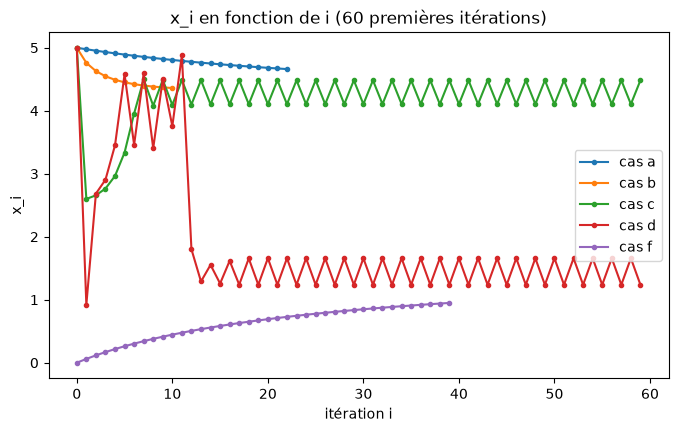

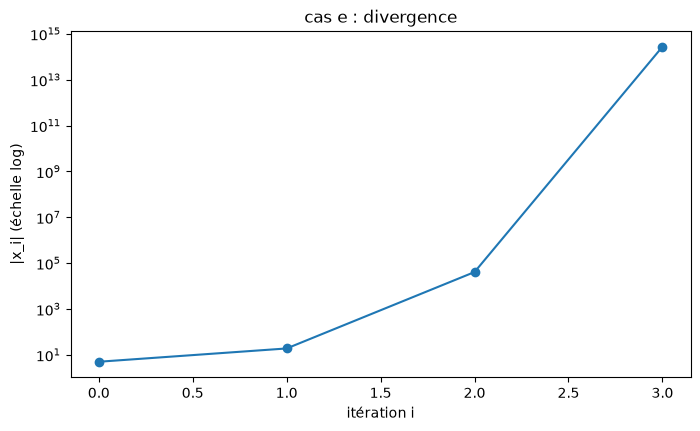

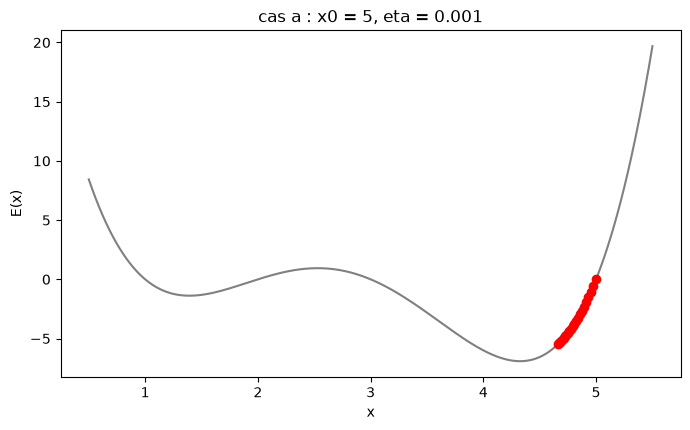

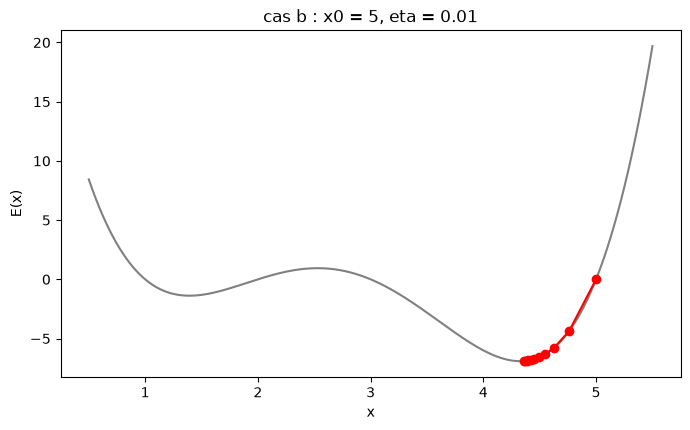

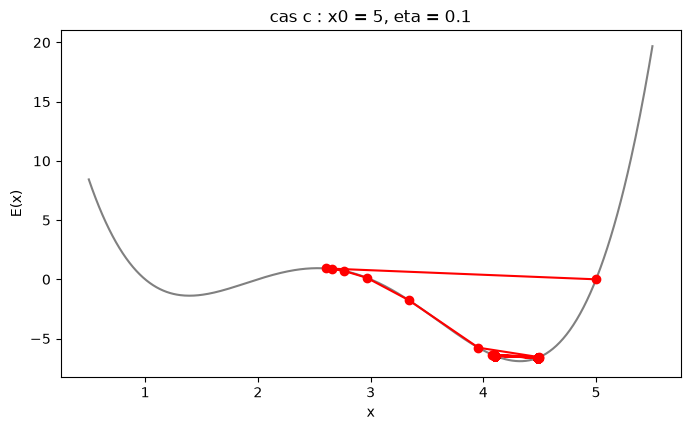

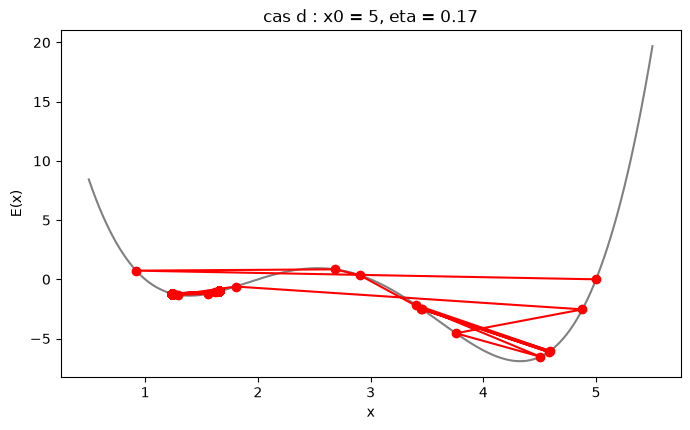

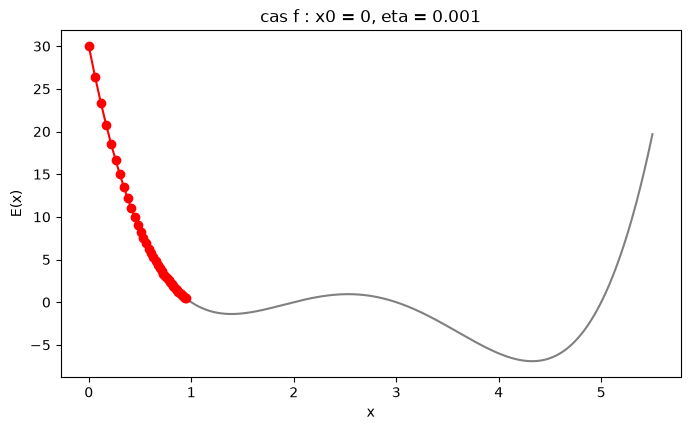

cas c, 8 derniers x : [4.48 4.1  4.48 4.1  4.48 4.1  4.48 4.1 ]
cas d, 8 derniers x : [1.24 1.66 1.24 1.66 1.24 1.66 1.24 1.66]


In [40]:
# (i) x_i en fonction de i, pour tous les cas sauf (e)
for k in [0, 1, 2, 3, 5]:
    plt.plot(resultats[k][:60], ".-", label="cas " + noms[k])
plt.xlabel("itération i")
plt.ylabel("x_i")
plt.title("x_i en fonction de i (60 premières itérations)")
plt.legend()
plt.show()

# (i) bis : le cas (e) à part, car x devient énorme
plt.plot(np.abs(resultats[4]), "o-")
plt.yscale("log")
plt.xlabel("itération i")
plt.ylabel("|x_i| (échelle log)")
plt.title("cas e : divergence")
plt.show()

# (ii) les points (x_i, E(x_i)) sur la courbe de E, un graphe par cas
for k in [0, 1, 2, 3, 5]:
    x_liste = np.array(resultats[k])
    plt.plot(xx, E(xx), color="grey")
    plt.plot(x_liste, E(x_liste), "o-", color="red")
    plt.title("cas " + noms[k] + " : x0 = " + str(liste_cas[k][0]) + ", eta = " + str(liste_cas[k][1]))
    plt.xlabel("x")
    plt.ylabel("E(x)")
    plt.show()

print("cas c, 8 derniers x :", np.round(resultats[2][-8:], 2))
print("cas d, 8 derniers x :", np.round(resultats[3][-8:], 2))

**Comportement de (c) et (d) :**

**Cas (c), $\eta = 0{,}1$ :** au début, la suite fait de grands sauts. Ensuite, elle se met à sauter toujours entre les deux mêmes valeurs : $4{,}10$, puis $4{,}48$, puis $4{,}10$, puis $4{,}48$… Ces deux valeurs sont de chaque côté du minimum global ($4{,}33$). La suite saute donc par-dessus le minimum à chaque itération, sans jamais s'en rapprocher. On dit que c'est une **oscillation entretenue** : elle ne diminue jamais, et l'algorithme ne s'arrête qu'en atteignant `nmax`.

**Cas (d), $\eta = 0{,}17$ :** le premier pas est tellement grand que la suite passe directement de $5$ à $0{,}92$, de l'autre côté de la bosse. Ensuite, elle se déplace de façon désordonnée et passe plusieurs fois d'un creux à l'autre. Pour finir, elle se bloque elle aussi à sauter entre deux valeurs, $1{,}24$ et $1{,}66$, de chaque côté du minimum **local** ($1{,}39$) cette fois. C'est donc d'abord un comportement **irrégulier**, puis une oscillation entretenue.

**Comparaison :** dans les cas (a), (b) et (f), la suite avance toujours dans le même sens vers le minimum, sans jamais le dépasser. Elle ne fait pas d'allers-retours. On parle de **convergence monotone**.

## Question 6 [Théorie]

**Démonstration.** 
On note $e_i = x_i - x^*$ l'erreur à l'itération $i$ (la distance entre $x_i$ et le minimum). On suppose que $x_i$ est proche de $x^*$, pour pouvoir utiliser Taylor.
Taylor à l'ordre 1 de $E'$ autour de $x^*$ :
$$E'(x_i) \approx E'(x^*) + E''(x^*)(x_i - x^*) = E''(x^*)\,e_i \quad\text{car } E'(x^*)=0 \text{ (c'est un minimum).}$$
On soustrait $x^*$ des deux côtés de la mise à jour :
$$e_{i+1} = x_{i+1}-x^* = (x_i - x^*) - \eta E'(x_i) \approx e_i - \eta E''(x^*)\,e_i = \big(1-\eta E''(x^*)\big)\,e_i.$$

Donc l'erreur est multipliée à chaque itération par le facteur $q = 1-\eta E''(x^*)$, soit $e_i \approx q^i e_0$.

**(a) Conditions** (avec $E''(x^*)>0$ puisque c'est un minimum) :

En appliquant la relation $e_{i+1} \approx q\, e_i$ plusieurs fois, on obtient :
$$e_1 = q\,e_0, \quad e_2 = q^2 e_0, \quad \dots, \quad e_i = q^i e_0$$
L'erreur $e_i$ suit donc une suite géométrique de raison $q$.

- **Convergence locale** : l'algorithme converge si l'erreur tend vers 0, c'est-à-dire si $q^i e_0 \to 0$. Or une suite géométrique $q^i$ tend vers 0 si et seulement si $|q| < 1$. Par exemple, avec $q = 0{,}5$ on obtient $0{,}5 \to 0{,}25 \to 0{,}125 \to \dots \to 0$, mais avec $q = 2$ on obtient $2 \to 4 \to 8 \to \dots$ qui explose. Donc :

  Convergence $\iff |q|<1 \iff -1 < 1-\eta E''(x^*) < 1 \iff \boxed{0 < \eta < \dfrac{2}{E''(x^*)}}$

  En effet, $-1 < 1 - \eta E''(x^*) < 1 \iff -2 < -\eta E''(x^*) < 0 \iff 0 < \eta E''(x^*) < 2 \iff 0 < \eta < \dfrac{2}{E''(x^*)}$.

- **Sans oscillation** : le signe de $e_i$ indique de quel côté du minimum on se trouve ($e_i > 0$ : à droite de $x^*$, $e_i < 0$ : à gauche).
  - Si $q \ge 0$, alors $e_i = q^i e_0$ garde toujours le même signe que $e_0$ : on reste du même côté du minimum, donc pas d'oscillation.
  - Si $q < 0$, le signe de $q^i$ alterne ($+, -, +, -, \dots$) : on passe d'un côté à l'autre du minimum à chaque pas, donc il y a oscillation.

  Il faut donc, en plus de $|q|<1$, que $q \ge 0$ :
  $$q \ge 0 \iff 1 - \eta E''(x^*) \ge 0 \iff \eta E''(x^*) \le 1 \iff \boxed{0 < \eta \le \dfrac{1}{E''(x^*)}}$$

**Interprétation :**
- si $0 < \eta \le 1/E''$ : $0 \le q < 1$, l'erreur diminue sans changer de signe : **convergence sans oscillation** ;
- si $1/E'' < \eta < 2/E''$ : $-1 < q < 0$, l'erreur change de signe à chaque pas mais diminue : **oscillation amortie** (on converge quand même) ;
- si $\eta > 2/E''$ : $q < -1$, donc $|q| > 1$, l'erreur grandit à chaque pas : on s'éloigne du minimum, **pas de convergence**.

**(b) Calcul numérique des seuils**

On a $E''(x) = 12x^2 - 66x + 82$. On prend les deux minima trouvés à la question 1, arrondis à 2 décimales.

**Minimum local $x_1^* \approx 1{,}39$ :**

$$E''(x_1^*) = 12 \times (1{,}39)^2 - 66 \times 1{,}39 + 82$$
$$= 12 \times 1{,}9321 - 91{,}74 + 82$$
$$= 23{,}19 - 91{,}74 + 82 \approx 13{,}45$$

$$\frac{1}{E''(x_1^*)} = \frac{1}{13{,}45} \approx 0{,}074 \qquad\qquad \frac{2}{E''(x_1^*)} = \frac{2}{13{,}45} \approx 0{,}149$$

**Minimum global $x_2^* \approx 4{,}33$ :**

$$E''(x_2^*) = 12 \times (4{,}33)^2 - 66 \times 4{,}33 + 82$$
$$= 12 \times 18{,}7489 - 285{,}78 + 82$$
$$= 224{,}99 - 285{,}78 + 82 \approx 21{,}21$$

$$\frac{1}{E''(x_2^*)} = \frac{1}{21{,}21} \approx 0{,}047 \qquad\qquad \frac{2}{E''(x_2^*)} = \frac{2}{21{,}21} \approx 0{,}094$$

**Résumé :**
- autour du minimum local $1{,}39$ : convergence sans oscillation si $\eta \le 0{,}074$, convergence (avec oscillation) si $\eta < 0{,}149$ ;
- autour du minimum global $4{,}33$ : convergence sans oscillation si $\eta \le 0{,}047$, convergence (avec oscillation) si $\eta < 0{,}094$.

  
**(c) Explication des cas :**
- **(b) $\eta=0{,}01$** : $0{,}01 < 0{,}0475$ → convergence **monotone** vers $4{,}326$ ($q = 0{,}79$). ✔
- **(c) $\eta=0{,}1$** : $0{,}1 > 0{,}0949$ → le minimum global est **instable** ($q=-1{,}11$, $|q|>1$) : on ne peut pas y converger, d'où l'oscillation entretenue. (Pour le minimum local, $0{,}1 < 0{,}1497$ serait convenable, mais on n'y arrive jamais car le premier saut nous laisse dans le bassin de droite.)
- **(d) $\eta=0{,}17$** : $0{,}17$ dépasse **les deux** seuils de convergence ($0{,}1497$ et $0{,}0949$) → aucun minimum n'est stable, la DG ne peut converger nulle part : elle erre puis tourne en rond.
- **(e) $\eta=1$** : très au-dessus de tous les seuils ($q\approx-20$) → l'erreur est multipliée par ~20 à chaque pas : **divergence**.

## Question 7 [Analyse] – Bassins d'attraction

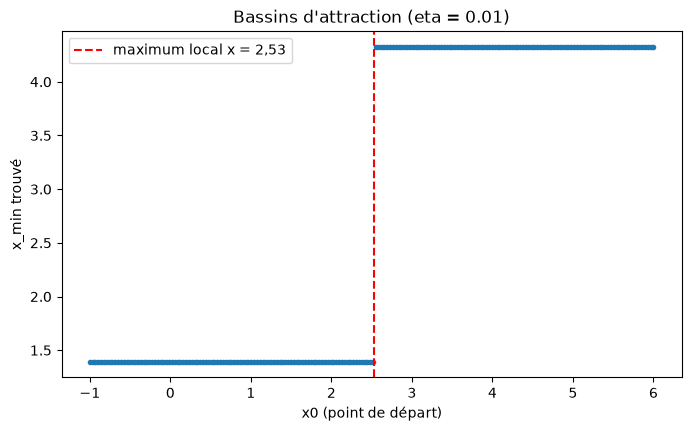

Premier x0 qui mène au minimum global : 2.55


In [41]:
# 200 points de départ entre -1 et 6
liste_x0 = np.linspace(-1, 6, 200)
liste_xmin = []

# pour chaque point de départ, on lance la descente et on garde le x_min trouvé
for x0 in liste_x0:
    x_min, i, list_x = descente_gradient(dE, x0, 0.01, eps=1e-6)
    liste_xmin.append(x_min)

# graphe : x_min trouvé en fonction du point de départ
plt.plot(liste_x0, liste_xmin, ".")
plt.axvline(2.53, color="red", linestyle="--", label="maximum local x = 2,53")
plt.xlabel("x0 (point de départ)")
plt.ylabel("x_min trouvé")
plt.title("Bassins d'attraction (eta = 0.01)")
plt.legend()
plt.show()

# on cherche le premier x0 qui mène au minimum global (x_min > 3)
for k in range(len(liste_x0)):
    if liste_xmin[k] > 3:
        print("Premier x0 qui mène au minimum global :", round(liste_x0[k], 2))
        break

**Réponse :** tous les $x_0 < 2{,}53$ mènent au minimum local $1{,}393$, tous les $x_0 > 2{,}53$ au minimum global $4{,}326$. La frontière correspond au **maximum local** $x\approx2{,}531$ de $E$ (là où $E'=0$ et $E''<0$) : c'est le « sommet de la colline » qui sépare les deux vallées.

**Conséquence :** la DG ne trouve que le minimum de la vallée où l'on part. Pour une fonction non convexe, elle ne garantit pas le minimum global. En pratique on **relance la DG depuis plusieurs points de départ** (aléatoires) et on garde le meilleur résultat (ou on utilise des variantes stochastiques qui peuvent sortir d'une vallée).

## Question 8 [Débogage] – Critère d'arrêt

### (a) Influence de $\varepsilon$ sur le cas (f)

In [8]:
x_star = racines[0]
for eps in [1e-2, 1e-4, 1e-6]:
    xm, n, _ = descente_gradient(dE, 0, 0.001, eps=eps, nmax=10000)
    print(f"eps = {eps:.0e} : x_min = {xm:.6f}, {n:4d} itérations, distance au vrai minimum = {abs(xm - x_star):.2e}")

eps = 1e-02 : x_min = 0.949407,   39 itérations, distance au vrai minimum = 4.43e-01
eps = 1e-04 : x_min = 1.385519,  312 itérations, distance au vrai minimum = 7.23e-03
eps = 1e-06 : x_min = 1.392675,  653 itérations, distance au vrai minimum = 7.31e-05


Avec $\varepsilon=0{,}01$, l'algorithme s'arrête à $x\approx0{,}949$, soit à **≈0,44 du vrai minimum** $1{,}393$ — c'est énorme comparé à $\varepsilon$ !

**Pourquoi ?** Le pas vaut $|x_{i+1}-x_i| = \eta\,|E'(x_i)|$. Avec $\eta=0{,}001$, il suffit que $|E'(x_i)| < 10$ pour que le pas soit $<0{,}01$. Or en $x=0{,}95$ la pente vaut encore ≈ $-6$ : on n'est pas au fond, mais on avance trop lentement pour que le critère le voie. **Un petit pas peut venir d'un petit $\eta$, pas forcément d'une pente nulle.** (Avec un $\eta$ très petit, le critère s'arrête même au tout premier pas.)

### (b) Critère fondé sur $E'(x_i)$

Au minimum, $E'(x^*)=0$. On s'arrête donc quand $|E'(x_i)| < \varepsilon$ : c'est une mesure directe de « on est au fond », indépendante de $\eta$.

In [9]:
def descente_gradient_grad(dE, x0, eta, eps=0.01, nmax=1000):
    '''Meme DG, mais arret quand |E'(x_i)| < eps.'''
    x = x0; xs = [x]
    for i in range(1, nmax + 1):
        g = dE(x)
        if abs(g) < eps:
            return x, i - 1, xs
        x = x - eta * g
        xs.append(x)
        if not np.isfinite(x) or abs(x) > 1e10:
            print("  ! Divergence"); return x, i, xs
    return x, nmax, xs

print("Critère       cas    x_min      itérations   |x_min - x*|")
for k in ['a', 'b', 'f']:
    x0, eta = cas[k]
    xs_ref = racines[2] if x0 == 5 else racines[0]
    xm1, n1, _ = descente_gradient(dE, x0, eta)
    xm2, n2, _ = descente_gradient_grad(dE, x0, eta, nmax=10000)
    print(f"|dx|<0.01    ({k})  {xm1:8.4f}   {n1:6d}       {abs(xm1-xs_ref):.2e}")
    print(f"|E'|<0.01    ({k})  {xm2:8.4f}   {n2:6d}       {abs(xm2-xs_ref):.2e}")

Critère       cas    x_min      itérations   |x_min - x*|
|dx|<0.01    (a)    4.6615       22       3.35e-01
|E'|<0.01    (a)    4.3268      318       4.66e-04
|dx|<0.01    (b)    4.3610       10       3.47e-02
|E'|<0.01    (b)    4.3268       28       4.72e-04
|dx|<0.01    (f)    0.9494       39       4.43e-01
|E'|<0.01    (f)    1.3920      481       7.39e-04


**Comparaison :** le critère $|E'(x_i)|<\varepsilon$ demande plus d'itérations quand $\eta$ est petit, mais il donne toujours un point proche du vrai minimum (erreur ≈ $\varepsilon / E''(x^*)$, de l'ordre de $10^{-3}$), quel que soit $\eta$. L'ancien critère pouvait s'arrêter à 0,3–0,4 du minimum. En pratique on combine souvent les deux, plus `nmax`.

### (c) Le bug `if x_new - x < eps:`

In [10]:
x0, eta = 5, 0.01
x_new = x0 - eta * dE(x0)
print(f"E'(5) = {dE(5)},  x_new = {x_new},  x_new - x = {x_new - x0:.2f}  < 0.01 ? {x_new - x0 < 0.01}")

E'(5) = 24,  x_new = 4.76,  x_new - x = -0.24  < 0.01 ? True


**Explication :** en $x_0=5$ la pente est positive ($E'(5)=24$), donc la DG **descend vers la gauche** : $x_1 = 5 - 0{,}01\times24 = 4{,}76$. La différence $x_{new}-x = -0{,}24$ est **négative**, donc forcément $< 0{,}01$ : le test est vrai dès la première itération et le programme s'arrête à 4,76. Sans valeur absolue, le test ne mesure pas la *taille* du pas : n'importe quel pas vers la gauche, même énorme, est accepté comme « petit ».

**Quand le code marche quand même :** quand la suite est **croissante** ($x_{i+1} > x_i$ à chaque fois), c'est-à-dire quand on part à gauche d'un minimum ($E'(x_0)<0$) et qu'on converge sans osciller — par exemple le cas (f) ($x_0=0$, on monte vers 1,39). Dès qu'il y a oscillation, le premier pas vers la gauche arrête l'algorithme.

# Partie 2 – Descente de gradient pour la régression linéaire

On cherche la droite $\hat y = ax+b$ qui passe au mieux dans un nuage de points. On minimise la somme des carrés des erreurs $E(a,b)=\sum_i(\hat y_i - y_i)^2$. Même principe qu'en partie 1, mais avec **deux** variables : on fait un pas dans chaque direction selon la dérivée partielle correspondante.

## Question 1 [Calcul]

Avec $r_i = \hat y_i - y_i = ax_i + b - y_i$ et la dérivée d'un carré $(u^2)' = 2uu'$ :

$$\frac{\partial E}{\partial a} = \sum_{i=1}^n 2(ax_i+b-y_i)\,x_i = 2\,\mathbf{x}^\top \mathbf{r}
\qquad
\frac{\partial E}{\partial b} = \sum_{i=1}^n 2(ax_i+b-y_i) = 2\sum_i r_i = 2\,\mathbf{1}^\top\mathbf{r}$$

où $\mathbf{r} = a\mathbf{x} + b - \mathbf{y}$ est le vecteur des résidus. En numpy : `2 * x @ r` et `2 * r.sum()`.

## Question 2 [Code]

In [11]:
def cout(a, b, x, y, moyenne=False):
    r = a * x + b - y
    E = np.sum(r**2)
    return E / len(x) if moyenne else E

def dg_regression(x, y, eta, nmax, a0=0.0, b0=0.0, moyenne=False):
    '''DG vectorisee pour E(a,b) (somme, ou moyenne si moyenne=True).
    Renvoie a, b, la liste des E, la trajectoire [(a_i, b_i)] et le statut.'''
    n = len(x)
    c = 1 / n if moyenne else 1
    a, b = a0, b0
    Es, traj = [cout(a, b, x, y, moyenne)], [(a, b)]
    for i in range(nmax):
        r = a * x + b - y              # residus, calcules UNE fois au point (a_i, b_i)
        grad_a = c * 2 * (x @ r)
        grad_b = c * 2 * r.sum()
        a, b = a - eta * grad_a, b - eta * grad_b   # mise a jour simultanee
        if not (np.isfinite(a) and np.isfinite(b)) or max(abs(a), abs(b)) > 1e10:
            return a, b, Es, traj, f'divergé (itération {i+1})'
        Es.append(cout(a, b, x, y, moyenne)); traj.append((a, b))
    return a, b, Es, traj, 'nmax atteint'

**[Débogage]** Si l'on écrit `a = a - eta*grad_a` **puis** qu'on recalcule les résidus pour `grad_b`, alors $\partial E/\partial b$ est évalué au point $(a_{i+1}, b_i)$ au lieu de $(a_i,b_i)$. On ne suit plus le vrai gradient : on fait en réalité une « descente par coordonnées » (on optimise $a$, puis $b$ avec le nouveau $a$). Ce n'est plus l'algorithme demandé et la trajectoire est différente.

**Est-ce grave ici ?** Pas vraiment : $E$ est quadratique et convexe, cette variante converge aussi vers le même minimum (elle peut même être un peu plus stable). Mais c'est une erreur d'implémentation : en général (réseaux de neurones, etc.) les résultats ne correspondent plus à la théorie de la DG. L'astuce `a, b = a - ..., b - ...` en Python évite le problème.

## Question 3 [Prédiction]

*Prédiction (avant exécution)* : intuitivement, un pas 10 fois plus grand fait avancer 10 fois plus vite… **sauf** si le pas dépasse le seuil de stabilité vu en partie 1 ($2/E''$). Ici $E$ est une **somme** sur 100 points, donc ses dérivées secondes sont grandes (≈ $2\sum x_i^2 \approx 200$) : le seuil est autour de $2/200 = 0{,}01$. On prédit donc que $\eta=0{,}01$ est à la limite et risque **de ne pas converger**, et que $\eta=1$ diverge.

In [12]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=100, n_features=1, noise=10, random_state=0)
x = X[:, 0]          # vecteur 1D des x_i

params = {'a': (0.001, 100), 'b': (0.001, 500), 'c': (0.001, 1000),
          'd': (0.01, 1000), 'e': (1, 1000)}
res2 = {k: dg_regression(x, y, eta, nm) for k, (eta, nm) in params.items()}

## Question 4 [Analyse]

cas     eta  nmax             a             b        E(a,b)   statut
(a)  0.001   100        42.619      -0.81418       11417.1   nmax atteint
(b)  0.001   500        42.619      -0.81418       11417.1   nmax atteint
(c)  0.001  1000        42.619      -0.81418       11417.1   nmax atteint
(d)   0.01  1000    1.0283e+10    8.7497e+09   1.49986e+22   divergé (itération 151)
(e)      1  1000   -7.3376e+10     -1.53e+10   1.36384e+19   divergé (itération 4)


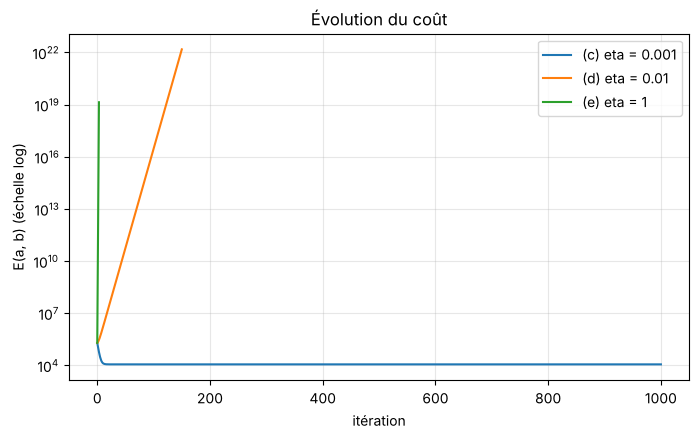

Cas (c) : E est stable (à 1e-6 près, en relatif) dès l'itération 38


In [13]:
print(f"{'cas':<4}{'eta':>7}{'nmax':>6}{'a':>14}{'b':>14}{'E(a,b)':>14}   statut")
for k, (eta, nm) in params.items():
    a, b, Es, _, st = res2[k]
    print(f"({k}){eta:>7}{nm:>6}{a:>14.5g}{b:>14.5g}{Es[-1]:>14.6g}   {st}")

plt.figure()
for k in ['c', 'd', 'e']:
    plt.semilogy(res2[k][2], label=f'({k}) eta = {params[k][0]}')
plt.xlabel('itération'); plt.ylabel('E(a, b) (échelle log)'); plt.title('Évolution du coût')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Es_c = np.array(res2['c'][2])
it_stab = np.argmax(np.abs(Es_c - Es_c[-1]) < 1e-6 * Es_c[-1])
print(f"Cas (c) : E est stable (à 1e-6 près, en relatif) dès l'itération {it_stab}")

**Constats :**
- (a), (b), (c) ($\eta=0{,}001$) donnent tous la même solution $a\approx42{,}62$, $b\approx-0{,}81$, $E\approx11\,417$. Même 100 itérations suffisent.
- (d) $\eta=0{,}01$ **diverge** : la prédiction « plus grand pas = plus rapide » est fausse ! Le coût explose (voir la courbe).
- (e) $\eta=1$ diverge en quelques itérations.
- **Inutile d'aller à 1000 itérations dans le cas (c)** : la courbe de E est plate après ~40 itérations. Les ~960 suivantes ne servent à rien — d'où l'intérêt d'un vrai critère d'arrêt (comme en Q8 partie 1).

## Question 5 [Théorie]

**(a)** Les dérivées secondes de $E$ sont :
$$\frac{\partial^2E}{\partial a^2} = 2\sum x_i^2,\qquad \frac{\partial^2E}{\partial a\,\partial b} = 2\sum x_i,\qquad \frac{\partial^2E}{\partial b^2} = 2n$$
$$H = 2\begin{pmatrix}\sum x_i^2 & \sum x_i\\ \sum x_i & n\end{pmatrix}$$
$H$ ne dépend pas de $(a,b)$ car $E$ est un **polynôme de degré 2** en $(a,b)$ : ses dérivées premières sont linéaires en $(a,b)$, donc ses dérivées secondes sont constantes. (Analogue de la partie 1, où $E''$ dépendait de $x$ car $E$ était de degré 4.)

In [14]:
n = len(x)
H = 2 * np.array([[np.sum(x**2), np.sum(x)],
                  [np.sum(x),    n        ]])
lam = np.linalg.eigvalsh(H)
eta_crit = 2 / lam.max()
print("H =\n", H)
print("valeurs propres :", lam)
print(f"pas critique 2/lambda_max = {eta_crit:.5f}")

H =
 [[203.8807  11.9616]
 [ 11.9616 200.    ]]
valeurs propres : [189.8224 214.0583]
pas critique 2/lambda_max = 0.00934


**(b)** $\lambda_{max}\approx214$, donc le pas critique vaut $2/\lambda_{max}\approx\mathbf{0{,}00934}$.
- $\eta=0{,}001 < 0{,}00934$ → convergence ✔ (cas a, b, c)
- $\eta=0{,}01 > 0{,}00934$ → divergence ✔ (cas d) : on dépasse le seuil de très peu, mais suffisamment.
- $\eta=1 \gg 0{,}00934$ → divergence très rapide ✔ (cas e)

**(c)** Avec l'erreur quadratique moyenne $\frac1n E$, la hessienne est divisée par $n$, donc le pas critique est **multiplié par $n=100$** : $2/\lambda_{max}\times n \approx 0{,}934$.

In [15]:
print(f"pas critique (MSE) = {n * eta_crit:.4f}")
for eta in [0.1, 1]:
    a, b, Es, _, st = dg_regression(x, y, eta, 1000, moyenne=True)
    print(f"MSE, eta = {eta}: a = {a:.5g}, b = {b:.5g}, MSE finale = {Es[-1]:.5g}  -> {st}")

pas critique (MSE) = 0.9343
MSE, eta = 0.1: a = 42.619, b = -0.81418, MSE finale = 114.17  -> nmax atteint
MSE, eta = 1: a = 1.0283e+10, b = 8.7497e+09, MSE finale = 1.4999e+20  -> divergé (itération 151)


Avec la MSE, $\eta=0{,}1$ converge vers la même solution ($a\approx42{,}62$, MSE $\approx114{,}17 = 11\,417/100$), et $\eta=1 > 0{,}934$ diverge encore.

**Pourquoi la moyenne ?** Avec la somme, le gradient (et le pas critique) dépend du **nombre d'exemples** : si on double les données, il faut diviser $\eta$ par 2. Avec la moyenne, l'échelle du gradient ne dépend plus de $n$ : le même $\eta$ fonctionne quelle que soit la taille du jeu de données (ou du mini-lot), et les valeurs de coût sont comparables entre jeux de tailles différentes.

## Question 6 [Analyse] [Réflexion]

In [16]:
from scipy import stats
lr = stats.linregress(x, y)
a_dg, b_dg = res2['c'][0], res2['c'][1]
print(f"linregress : a = {lr.slope:.6f}, b = {lr.intercept:.6f}, E = {cout(lr.slope, lr.intercept, x, y):.4f}")
print(f"DG (c)     : a = {a_dg:.6f}, b = {b_dg:.6f}, E = {cout(a_dg, b_dg, x, y):.4f}")

linregress : a = 42.619430, b = -0.814182, E = 11417.1486
DG (c)     : a = 42.619430, b = -0.814182, E = 11417.1486


**Constat :** les deux méthodes donnent les **mêmes** coefficients (à $10^{-12}$ près) et le même $E$. La DG retrouve bien la solution exacte des moindres carrés, à condition de bien choisir $\eta$.

**[Réflexion] Pourquoi la DG si une solution exacte existe ?** La solution exacte $\theta = (X^\top X)^{-1}X^\top y$ demande de construire et d'inverser une matrice $p\times p$ (coût ≈ $p^3$) et d'avoir toutes les données en mémoire. Situations où la DG est indispensable :
1. **Très grand nombre de variables** $p$ (texte, images, génomique : $p$ = $10^5$ à $10^6$) : inverser $X^\top X$ est trop coûteux ; un pas de DG coûte seulement $O(np)$.
2. **Très gros volume de données** qui ne tient pas en mémoire ou arrive en flux : la DG stochastique / par mini-lots traite les données petit à petit.
3. **Modèles sans solution analytique** : régression logistique, régularisation Lasso, réseaux de neurones… Il n'y a pas de formule fermée, seule l'optimisation itérative fonctionne.

## Question 7 [Visualisation]

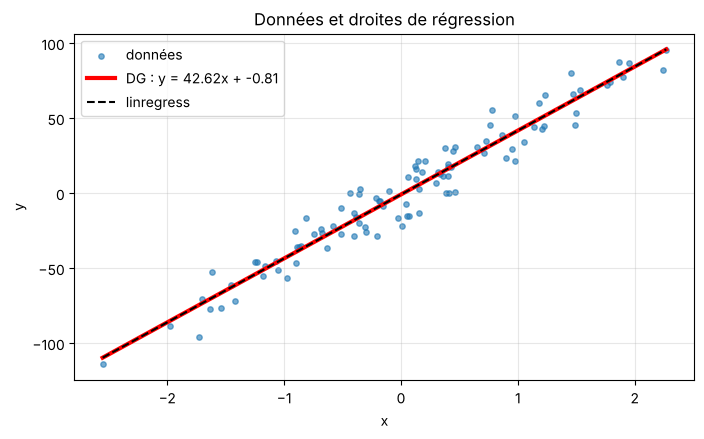

In [17]:
plt.scatter(x, y, s=15, alpha=0.6, label='données')
xl = np.array([x.min(), x.max()])
plt.plot(xl, a_dg * xl + b_dg, 'r-', lw=3, label=f'DG : y = {a_dg:.2f}x + {b_dg:.2f}')
plt.plot(xl, lr.slope * xl + lr.intercept, 'k--', lw=1.5, label='linregress')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3); plt.title('Données et droites de régression')
plt.show()

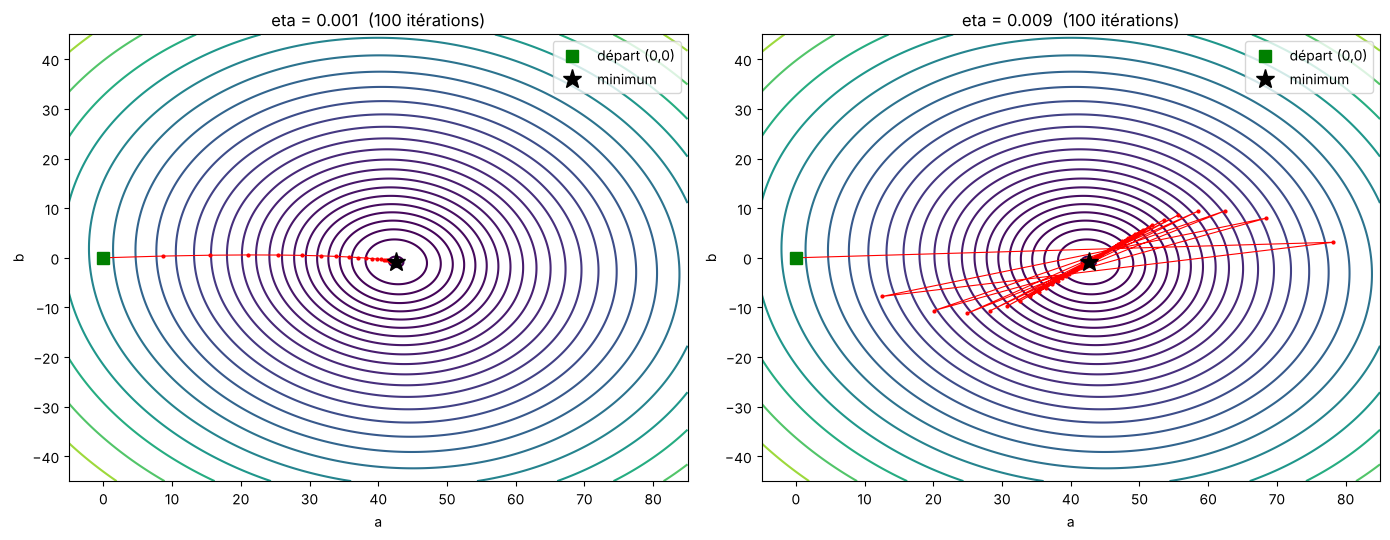

eta = 0.001: facteurs (1 - eta*lambda) = [0.8102 0.7859]
eta = 0.009: facteurs (1 - eta*lambda) = [-0.7084 -0.9265]


In [18]:
A, B = np.meshgrid(np.linspace(-5, 85, 300), np.linspace(-45, 45, 300))
# E(a,b) sur la grille, vectorise : on ajoute un axe pour les n points
Z = np.sum((A[..., None] * x + B[..., None] - y)**2, axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, eta in zip(axes, [0.001, 0.009]):
    _, _, Es, traj, st = dg_regression(x, y, eta, 100)
    traj = np.array(traj)
    ax.contour(A, B, Z, levels=np.geomspace(Z.min() * 1.01, Z.max(), 25), cmap='viridis')
    ax.plot(traj[:, 0], traj[:, 1], 'r.-', ms=4, lw=0.8)
    ax.plot(*traj[0], 'gs', ms=8, label='départ (0,0)')
    ax.plot(lr.slope, lr.intercept, 'k*', ms=14, label='minimum')
    ax.set_title(f'eta = {eta}  (100 itérations)'); ax.set_xlabel('a'); ax.set_ylabel('b'); ax.legend()
plt.tight_layout(); plt.show()

for eta in [0.001, 0.009]:
    print(f"eta = {eta}: facteurs (1 - eta*lambda) = {1 - eta * lam}")

**Description :**
- **$\eta=0{,}001$** : trajectoire **lisse**, presque en ligne droite, qui descend la « cuvette » perpendiculairement aux lignes de niveau et arrive au minimum sans le dépasser.
- **$\eta=0{,}009$** : trajectoire en **zigzag** : chaque pas traverse la vallée d'un bord à l'autre, en se rapprochant lentement du minimum.

**Explication :** c'est la question 6 de la partie 1 en 2D. Dans chaque direction propre de $H$, l'erreur est multipliée à chaque pas par $1-\eta\lambda$.
- Pour $\eta=0{,}001$ : facteurs ≈ $0{,}81$ et $0{,}79$, positifs → convergence **sans oscillation**.
- Pour $\eta=0{,}009$ : dans la direction de $\lambda_{max}=214$, le facteur vaut $1-0{,}009\times214 \approx -0{,}93$ : **négatif** (on change de côté à chaque pas) et proche de $-1$ (l'oscillation s'amortit très lentement). On est juste sous le seuil critique $0{,}00934$ : c'est une **oscillation amortie**. Un pas de plus ($0{,}01$) et c'est la divergence du cas (d).

# Pour aller plus loin (facultatif) – DG stochastique

SGD (mini-lots de 10) : a = 41.181, b = -2.419


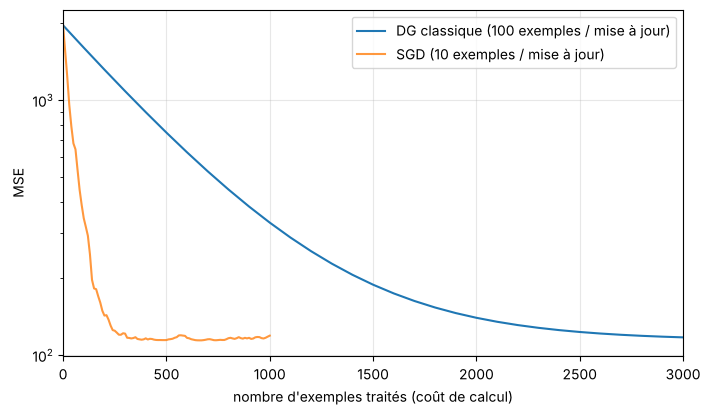

In [19]:
def dg_stochastique(x, y, eta, n_epoques, taille_lot=10, seed=0):
    '''SGD par mini-lots sur la MSE. Renvoie a, b et la MSE (sur tout le jeu) apres chaque mise a jour.'''
    rng = np.random.default_rng(seed)
    a = b = 0.0; Es = [cout(a, b, x, y, True)]
    n = len(x)
    for _ in range(n_epoques):
        for _ in range(n // taille_lot):
            idx = rng.choice(n, taille_lot, replace=False)
            r = a * x[idx] + b - y[idx]
            a, b = a - eta * 2 * np.mean(x[idx] * r), b - eta * 2 * np.mean(r)
            Es.append(cout(a, b, x, y, True))
    return a, b, Es

a_s, b_s, Es_s = dg_stochastique(x, y, 0.05, 10)
_, _, Es_full, _, _ = dg_regression(x, y, 0.05, 100, moyenne=True)
print(f"SGD (mini-lots de 10) : a = {a_s:.3f}, b = {b_s:.3f}")

plt.semilogy(np.arange(len(Es_full)) * 100, Es_full, label='DG classique (100 exemples / mise à jour)')
plt.semilogy(np.arange(len(Es_s)) * 10, Es_s, label='SGD (10 exemples / mise à jour)', alpha=0.8)
plt.xlabel("nombre d'exemples traités (coût de calcul)"); plt.ylabel('MSE'); plt.xlim(0, 3000)
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Comparaison :** à coût de calcul égal (nombre d'exemples traités), la SGD fait 10 fois plus de mises à jour et descend plus vite au début. En revanche sa courbe est **bruitée** (le gradient sur 10 exemples n'est qu'une estimation) et elle oscille autour du minimum au lieu de s'y poser exactement.

**Pourquoi pour les réseaux de neurones ?** Les jeux de données comptent des millions d'exemples : calculer le gradient exact sur tout le jeu à chaque pas serait beaucoup trop lent et ne tiendrait pas en mémoire (GPU). Un mini-lot donne une estimation suffisante pour beaucoup moins cher. En bonus, le bruit aide à sortir de mauvais minima locaux ou de points selles — ce qui répond au problème des bassins d'attraction vu en Q7 de la partie 1.